# Task 1

# 1. Imports, Random Seed Initialization, and Dataset Loading

In [1]:
import os
import pickle
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# Fix all random seeds for strict reproducibility (Section 4 requirement)
SEED = 42
np.random.seed(SEED)

# Load Task 1 dataset and respect the exact pre-defined train/test split
df_task1 = pd.read_csv("data/task1_promoter.csv")
train_df = df_task1[df_task1["split"] == "train"].reset_index(drop=True)
test_df  = df_task1[df_task1["split"] == "test"].reset_index(drop=True)

X_train_seqs, y_train = train_df["sequence"].tolist(), train_df["label"].values
X_test_seqs,  y_test  = test_df["sequence"].tolist(),  test_df["label"].values

print(f"Dataset loaded successfully: Total = {len(df_task1)} sequences (Length = {len(X_train_seqs[0])} bp)")
print(f"Train split: {len(train_df)} samples | Promoters (1): {sum(y_train==1)}, Non-promoters (0): {sum(y_train==0)}")
print(f"Test split : {len(test_df)} samples  | Promoters (1): {sum(y_test==1)}, Non-promoters (0): {sum(y_test==0)}")

Dataset loaded successfully: Total = 5719 sequences (Length = 81 bp)
Train split: 4575 samples | Promoters (1): 2287, Non-promoters (0): 2288
Test split : 1144 samples  | Promoters (1): 572, Non-promoters (0): 572


# 2. Feature Engineering: k-mers, Composition, Positional Windows & Biophysical Motifs


In [2]:
NUCLEOTIDES = ["A", "C", "G", "T"]

# Count normalized overlapping k-mers for each sequence.
def extract_kmer_features(sequences, k):
    """
    Computes normalized overlapping k-mer frequency vectors of length 4^k.
    For an 81 bp sequence, there are (81 - k + 1) overlapping substrings of length k.
    """
    kmers = ["".join(p) for p in product(NUCLEOTIDES, repeat=k)]
    kmer_to_idx = {km: i for i, km in enumerate(kmers)}
    n_kmers = len(kmers)
    
    X = np.zeros((len(sequences), n_kmers), dtype=np.float32)
    for row_idx, seq in enumerate(sequences):
        total_windows = len(seq) - k + 1
        for i in range(total_windows):
            km = seq[i : i + k]
            if km in kmer_to_idx:
                X[row_idx, kmer_to_idx[km]] += 1.0
        X[row_idx] /= total_windows
    feature_names = [f"kmer_{km}" for km in kmers]
    return X, feature_names


def pwm_log_odds_score(seq_window, consensus, match_prob=0.75, bg_prob=0.25):
    """
    Computes log-odds similarity score (in bits) of a sequence window against
    a known canonical consensus motif assuming uniform background nucleotide frequency.
    """
    score = 0.0
    mismatch_prob = (1.0 - match_prob) / 3.0
    for base, cons_base in zip(seq_window, consensus):
        p = match_prob if base == cons_base else mismatch_prob
        score += np.log2(p / bg_prob)
    return score


def max_motif_score_in_window(seq, start_idx, end_idx, consensus):
    """
    Scans a specific biological region [start_idx, end_idx) for the best match
    to a consensus motif and returns both the maximum score and its relative position.
    """
    w = len(consensus)
    best_score = -1e9
    for i in range(start_idx, end_idx - w + 1):
        s = pwm_log_odds_score(seq[i : i + w], consensus)
        if s > best_score:
            best_score = s
    return best_score


def extract_domain_and_positional_features(sequences):
    """
    Extracts mandatory & custom biological features required by Section 1.1:
    
    1. Mandatory Global Nucleotide Composition & GC Content (7 features):
       - Global A, C, G, T frequencies and total GC content (G + C).
       - Global GC skew = (G - C)/(G + C) and AT skew = (A - T)/(A + T), which capture
         strand asymmetry around bacterial transcription start sites.
         
    2. Custom Feature Set 1 — TSS-Aligned Positional Window Composition & Local Dinucleotides (62 features):
       - Biological Justification: All sequences are aligned on the TSS (+1 at index 60).
         Global k-mer counts lose positional context. Because bacterial promoters have distinct
         functional zones, we partition the 81 bp sequence into 6 biological windows:
           * Far upstream [-60 to -41] (indices 0..20)
           * -35 recognition region [-40 to -26] (indices 20..35)
           * Spacer region [-25 to -16] (indices 35..45)
           * -10 Pribnow box region [-15 to -5] (indices 45..56)
           * TSS initiation region [-4 to +6] (indices 56..66)
           * Downstream coding/5'-UTR region [+7 to +20] (indices 66..81)
         Plus localized 2-mer (dinucleotide) frequencies specifically inside the -35 (indices 22..34)
         and -10 (indices 45..57) boxes.
         
    3. Custom Feature Set 2 — Consensus Motif Log-Odds Scanning & DNA Duplex Melting Stability (10 features):
       - Biological Justification:
         (a) RNA polymerase sigma factors recognize degenerate versions of canonical motifs:
             -35 box (TTGACA around indices 20..36), -10 box (TATAAT around indices 44..57),
             extended -10 element (TGnTATAAT), and sigma54 -24/-12 boxes (TGGCAC / TTGCA).
         (b) Transcription initiation requires unwinding (melting) the DNA double helix at the -10
             and TSS regions. Using unified SantaLucia dinucleotide stacking free-energy parameters
             (dG in kcal/mol at 37 C), we compute DNA duplex stability across the -10 melting box
             and compare it against the global sequence background.
    """
    # Unified SantaLucia dinucleotide free energy parameters (dG_37 in kcal/mol)
    dG_map = {
        "AA": -1.00, "TT": -1.00, "AT": -0.88, "TA": -0.58,
        "CA": -1.45, "TG": -1.45, "GT": -1.44, "AC": -1.44,
        "CT": -1.28, "AG": -1.28, "GA": -1.30, "TC": -1.30,
        "CG": -2.17, "GC": -2.24, "GG": -1.84, "CC": -1.84,
    }
    dinucs = ["".join(p) for p in product(NUCLEOTIDES, repeat=2)]
    dinuc_idx = {d: i for i, d in enumerate(dinucs)}

    # Define TSS-aligned regions used for composition and stability features.
    windows = [
        ("up_far", 0, 20),
        ("box35", 20, 35),
        ("spacer", 35, 45),
        ("box10", 45, 56),
        ("tss", 56, 66),
        ("down", 66, 81),
    ]

    feature_names = ["global_A", "global_C", "global_G", "global_T", "global_GC", "global_GC_skew", "global_AT_skew"]
    for w_name, _, _ in windows:
        feature_names.extend([f"{w_name}_A", f"{w_name}_C", f"{w_name}_G", f"{w_name}_T", f"{w_name}_GC"])
    feature_names.extend([f"box35_dinuc_{d}" for d in dinucs])
    feature_names.extend([f"box10_dinuc_{d}" for d in dinucs])
    feature_names.extend([
        "motif_sigma70_35_score", "motif_sigma70_10_score",
        "dG_global", "dG_box35", "dG_box10_melting", "dG_tss", "dG_destabilization_10_vs_global"
    ])

    feats = np.zeros((len(sequences), len(feature_names)), dtype=np.float32)

    for row_idx, seq in enumerate(sequences):
        L = len(seq)
        # 1. Global composition & GC content
        a = seq.count("A") / L
        c = seq.count("C") / L
        g = seq.count("G") / L
        t = seq.count("T") / L
        gc = g + c
        gc_skew = (g - c) / (g + c + 1e-8)
        at_skew = (a - t) / (a + t + 1e-8)

        # 2. Custom Set 1: Windowed base/GC composition + localized -35 and -10 dinucleotides
        win_vals = []
        for _, w_s, w_e in windows:
            sub = seq[w_s:w_e]
            wL = len(sub)
            w_a, w_c, w_g, w_t = sub.count("A")/wL, sub.count("C")/wL, sub.count("G")/wL, sub.count("T")/wL
            win_vals.extend([w_a, w_c, w_g, w_t, w_g + w_c])

        local_2mers_35 = np.zeros(16, dtype=np.float32)
        sub35 = seq[22:34]
        for i in range(len(sub35) - 1):
            local_2mers_35[dinuc_idx[sub35[i : i + 2]]] += 1.0 / (len(sub35) - 1)

        local_2mers_10 = np.zeros(16, dtype=np.float32)
        sub10 = seq[45:57]
        for i in range(len(sub10) - 1):
            local_2mers_10[dinuc_idx[sub10[i : i + 2]]] += 1.0 / (len(sub10) - 1)

        # 3. Custom Set 2: Motif scanning & SantaLucia DNA duplex melting stability
        s_35 = max_motif_score_in_window(seq, 20, 36, "TTGACA")
        s_10 = max_motif_score_in_window(seq, 44, 57, "TATAAT")

        dg_global = np.mean([dG_map[seq[i : i + 2]] for i in range(L - 1)])
        dg_35     = np.mean([dG_map[seq[i : i + 2]] for i in range(23, 32)])
        dg_10     = np.mean([dG_map[seq[i : i + 2]] for i in range(46, 55)])
        dg_tss    = np.mean([dG_map[seq[i : i + 2]] for i in range(56, 64)])
        dg_diff   = dg_10 - dg_global

        row = (
            [a, c, g, t, gc, gc_skew, at_skew]
            + win_vals
            + list(local_2mers_35)
            + list(local_2mers_10)
            + [s_35, s_10, dg_global, dg_35, dg_10, dg_tss, dg_diff]
        )
        feats[row_idx] = row

    return feats, feature_names

# 3. Evaluating k-mer Sizes (k = 2, 3, 4, 5) on Training Set via 5-Fold CV

Evaluating k-mer sizes on training set using 5-fold Stratified CV...

--- k-mer Cross-Validation Summary Table ---
 k  num_features  CV_Accuracy_Mean  CV_Accuracy_Std  CV_F1_Mean  CV_ROC_AUC_Mean
 2            16            0.7773           0.0188      0.7721           0.8421
 3            64            0.7904           0.0180      0.7863           0.8576
 4           256            0.7810           0.0207      0.7769           0.8537
 5          1024            0.7364           0.0129      0.7359           0.8100

Selected Best k by 5-fold Cross-Validation: k = 3 (64 features)


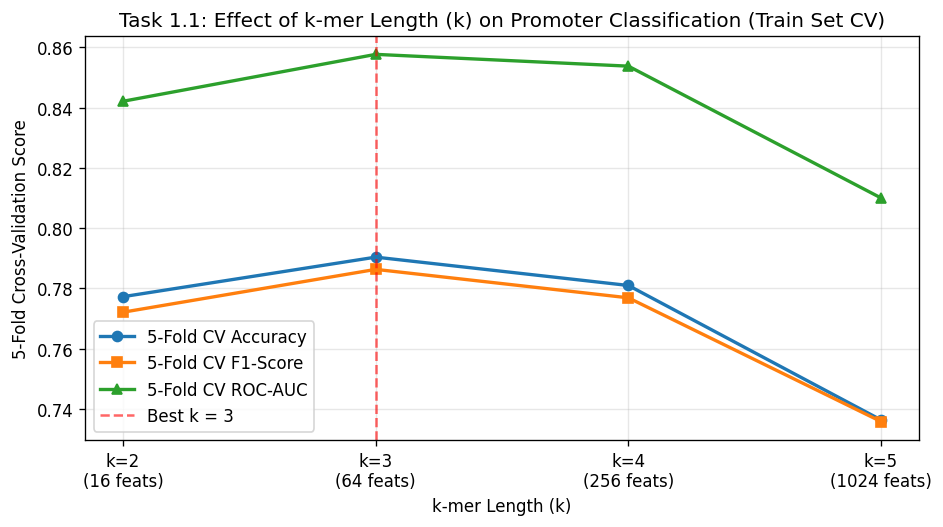

In [3]:
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
k_values = [2, 3, 4, 5]
k_results = []

print("Evaluating k-mer sizes on training set using 5-fold Stratified CV...")
for k in k_values:
    Xk_train, _ = extract_kmer_features(X_train_seqs, k)
    
    # Evaluate with both a linear model (Logistic Regression) and non-linear SVM
    pipe_lr = Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(C=1.0, max_iter=1000, random_state=SEED))
    ])
    scores = cross_validate(
        pipe_lr, Xk_train, y_train, cv=cv_splitter,
        scoring=["accuracy", "f1", "roc_auc"], n_jobs=-1
    )
    k_results.append({
        "k": k,
        "num_features": 4**k,
        "CV_Accuracy_Mean": scores["test_accuracy"].mean(),
        "CV_Accuracy_Std":  scores["test_accuracy"].std(),
        "CV_F1_Mean":       scores["test_f1"].mean(),
        "CV_ROC_AUC_Mean":  scores["test_roc_auc"].mean(),
    })

k_df = pd.DataFrame(k_results)
display_cols = ["k", "num_features", "CV_Accuracy_Mean", "CV_Accuracy_Std", "CV_F1_Mean", "CV_ROC_AUC_Mean"]
print("\n--- k-mer Cross-Validation Summary Table ---")
print(k_df[display_cols].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

best_k = int(k_df.loc[k_df["CV_F1_Mean"].idxmax(), "k"])
print(f"\nSelected Best k by 5-fold Cross-Validation: k = {best_k} ({4**best_k} features)")

# Plot how performance changes with k
plt.figure(figsize=(8, 4.5), dpi=120)
plt.plot(k_df["k"], k_df["CV_Accuracy_Mean"], marker="o", linewidth=2, label="5-Fold CV Accuracy")
plt.plot(k_df["k"], k_df["CV_F1_Mean"], marker="s", linewidth=2, label="5-Fold CV F1-Score")
plt.plot(k_df["k"], k_df["CV_ROC_AUC_Mean"], marker="^", linewidth=2, label="5-Fold CV ROC-AUC")
plt.axvline(best_k, color="red", linestyle="--", alpha=0.6, label=f"Best k = {best_k}")
plt.xticks(k_values, [f"k={k}\n({4**k} feats)" for k in k_values])
plt.xlabel("k-mer Length (k)")
plt.ylabel("5-Fold Cross-Validation Score")
plt.title("Task 1.1: Effect of k-mer Length (k) on Promoter Classification (Train Set CV)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("task1_kmer_cv_comparison.png", dpi=300)
plt.show()

# 4. Building Combined Feature Matrix and Verifying Feature Group Contributions

In [4]:
# Extract best k-mer features (k=3 -> 64 features)
X_kmer_train, kmer_names = extract_kmer_features(X_train_seqs, best_k)
X_kmer_test,  _          = extract_kmer_features(X_test_seqs,  best_k)

# Extract biological & positional features (79 features)
X_bio_train, bio_names = extract_domain_and_positional_features(X_train_seqs)
X_bio_test,  _         = extract_domain_and_positional_features(X_test_seqs)

# Combine into full feature matrix (143 features total)
X_train_full = np.hstack([X_kmer_train, X_bio_train])
X_test_full  = np.hstack([X_kmer_test,  X_bio_test])
all_feature_names = kmer_names + bio_names

print(f"Final Training Feature Matrix Shape: {X_train_full.shape}")
print(f"Final Test Feature Matrix Shape    : {X_test_full.shape}")

# Quick CV ablation check on training set to justify adding biological/positional features in the report
for desc, X_sub in [
    (f"Only {best_k}-mer frequencies ({X_kmer_train.shape[1]} feats)", X_kmer_train),
    (f"Only Positional + Motif + Stability ({X_bio_train.shape[1]} feats)", X_bio_train),
    (f"Combined Full Feature Vector ({X_train_full.shape[1]} feats)", X_train_full),
]:
    pipe = Pipeline([("scaler", StandardScaler()), ("svm", SVC(C=1.0, kernel="rbf", random_state=SEED))])
    sc = cross_validate(pipe, X_sub, y_train, cv=cv_splitter, scoring=["accuracy", "f1", "roc_auc"], n_jobs=-1)
    print(f"{desc:52s} -> CV Acc: {sc['test_accuracy'].mean():.4f} | F1: {sc['test_f1'].mean():.4f} | AUC: {sc['test_roc_auc'].mean():.4f}")


Final Training Feature Matrix Shape: (4575, 140)
Final Test Feature Matrix Shape    : (1144, 140)
Only 3-mer frequencies (64 feats)                    -> CV Acc: 0.7932 | F1: 0.7867 | AUC: 0.8579
Only Positional + Motif + Stability (76 feats)       -> CV Acc: 0.8149 | F1: 0.8092 | AUC: 0.8793
Combined Full Feature Vector (140 feats)             -> CV Acc: 0.8267 | F1: 0.8213 | AUC: 0.8928


# 5. Hyperparameter Tuning of LR, SVM, Random Forest, and XGBoost on Train Set


In [5]:
# IMPORTANT RULE (Section 4): All scaling and hyperparameter tuning are performed inside
# Pipelines on the training set only via 5-fold Stratified Cross-Validation.

N_WORKERS = max(1, (os.cpu_count() or 4) - 1)
print(f"Running GridSearchCV using {N_WORKERS} parallel workers (leaving 1 core free for OS)...")

models_and_grids = {
    "Logistic Regression": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=1000, random_state=SEED))
        ]),
        {
            "clf__C": [0.01, 0.05, 0.1, 0.5, 1.0, 5.0],
        }
    ),
    "SVM": (
        Pipeline([
            ("scaler", StandardScaler()),
            # probability=False makes GridSearchCV 6x faster!
            ("clf", SVC(kernel="rbf", probability=False, cache_size=1000, random_state=SEED))
        ]),
        {
            "clf__C": [0.5, 1.0, 2.0],
            "clf__gamma": ["scale", 0.005],
        }
    ),
    "Random Forest": (
        Pipeline([
            ("scaler", StandardScaler()),
            # n_jobs=1 here prevents thread oversubscription inside GridSearchCV
            ("clf", RandomForestClassifier(random_state=SEED, n_jobs=1))
        ]),
        {
            "clf__n_estimators": [200, 300],
            "clf__max_depth": [12, 18, None],
            "clf__min_samples_split": [2, 5],
            "clf__max_features": ["sqrt"],
        }
    ),
}


models_and_grids["XGBoost"] = (
    Pipeline([
        ("scaler", StandardScaler()),
        ("clf", XGBClassifier(
            eval_metric="logloss",
            random_state=SEED,
            n_jobs=1,  # Keep n_jobs=1 inside GridSearchCV
        ))
    ]),
    {
        "clf__n_estimators": [150, 250],
        "clf__learning_rate": [0.03, 0.05, 0.1],
        "clf__max_depth": [4, 6],
        "clf__subsample": [0.8],
        "clf__colsample_bytree": [0.8],
    }
)


best_estimators = {}
cv_tuning_summary = []

for model_name, (pipeline, param_grid) in models_and_grids.items():
    print(f"Tuning {model_name} via 5-fold Stratified Cross-Validation...")
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv_splitter,
        n_jobs=N_WORKERS,
        refit=True,
    )
    grid.fit(X_train_full, y_train)
    best_estimators[model_name] = grid.best_estimator_
    cv_tuning_summary.append({
        "Model": model_name,
        "Best_CV_ROC_AUC": grid.best_score_,
        "Best_Params": grid.best_params_,
    })
    print(f"  -> Best CV ROC-AUC: {grid.best_score_:.4f} | Best Params: {grid.best_params_}")

cv_summary_df = pd.DataFrame(cv_tuning_summary)

Running GridSearchCV using 7 parallel workers (leaving 1 core free for OS)...
Tuning Logistic Regression via 5-fold Stratified Cross-Validation...
  -> Best CV ROC-AUC: 0.8925 | Best Params: {'clf__C': 0.01}
Tuning SVM via 5-fold Stratified Cross-Validation...
  -> Best CV ROC-AUC: 0.8938 | Best Params: {'clf__C': 1.0, 'clf__gamma': 0.005}
Tuning Random Forest via 5-fold Stratified Cross-Validation...
  -> Best CV ROC-AUC: 0.8778 | Best Params: {'clf__max_depth': 12, 'clf__max_features': 'sqrt', 'clf__min_samples_split': 5, 'clf__n_estimators': 300}
Tuning XGBoost via 5-fold Stratified Cross-Validation...
  -> Best CV ROC-AUC: 0.8920 | Best Params: {'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.03, 'clf__max_depth': 4, 'clf__n_estimators': 250, 'clf__subsample': 0.8}


# 6. Test Set Evaluation: Accuracy, Precision, Recall, F1, MCC, and ROC-AUC

In [6]:
test_metrics_list = []
roc_curves_data = {}
confusion_matrices = {}

for model_name, clf in best_estimators.items():
    y_pred = clf.predict(X_test_full)
    
    # Use predict_proba if available, or decision_function for fast SVC
    if hasattr(clf, "predict_proba"):
        y_score = clf.predict_proba(X_test_full)[:, 1]
    else:
        y_score = clf.decision_function(X_test_full)
    
    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec  = recall_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred)
    mcc  = matthews_corrcoef(y_test, y_pred)
    auc  = roc_auc_score(y_test, y_score)
    cm   = confusion_matrix(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_score)
    
    test_metrics_list.append({
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "MCC": mcc,
        "ROC-AUC": auc,
    })
    roc_curves_data[model_name] = (fpr, tpr, auc)
    confusion_matrices[model_name] = cm

results_df = pd.DataFrame(test_metrics_list).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
print("\n================ TASK 1 TEST SET PERFORMANCE TABLE ================")
print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

best_task1_model_name = results_df.loc[0, "Model"]
print(f"\nBest Conventional Model on Task 1 Test Set: {best_task1_model_name} (F1 = {results_df.loc[0, 'F1-Score']:.4f}, ROC-AUC = {results_df.loc[0, 'ROC-AUC']:.4f})")



================ TASK 1 TEST SET PERFORMANCE TABLE ================
              Model  Accuracy  Precision  Recall  F1-Score    MCC  ROC-AUC
                SVM    0.8182     0.8370  0.7902    0.8129 0.6374   0.8906
Logistic Regression    0.8129     0.8231  0.7972    0.8099 0.6262   0.8936
            XGBoost    0.8138     0.8330  0.7850    0.8083 0.6287   0.8848
      Random Forest    0.8042     0.8258  0.7710    0.7975 0.6097   0.8709

Best Conventional Model on Task 1 Test Set: SVM (F1 = 0.8129, ROC-AUC = 0.8906)


# 7. Visualizing Confusion Matrices and Combined ROC Curves for All Models

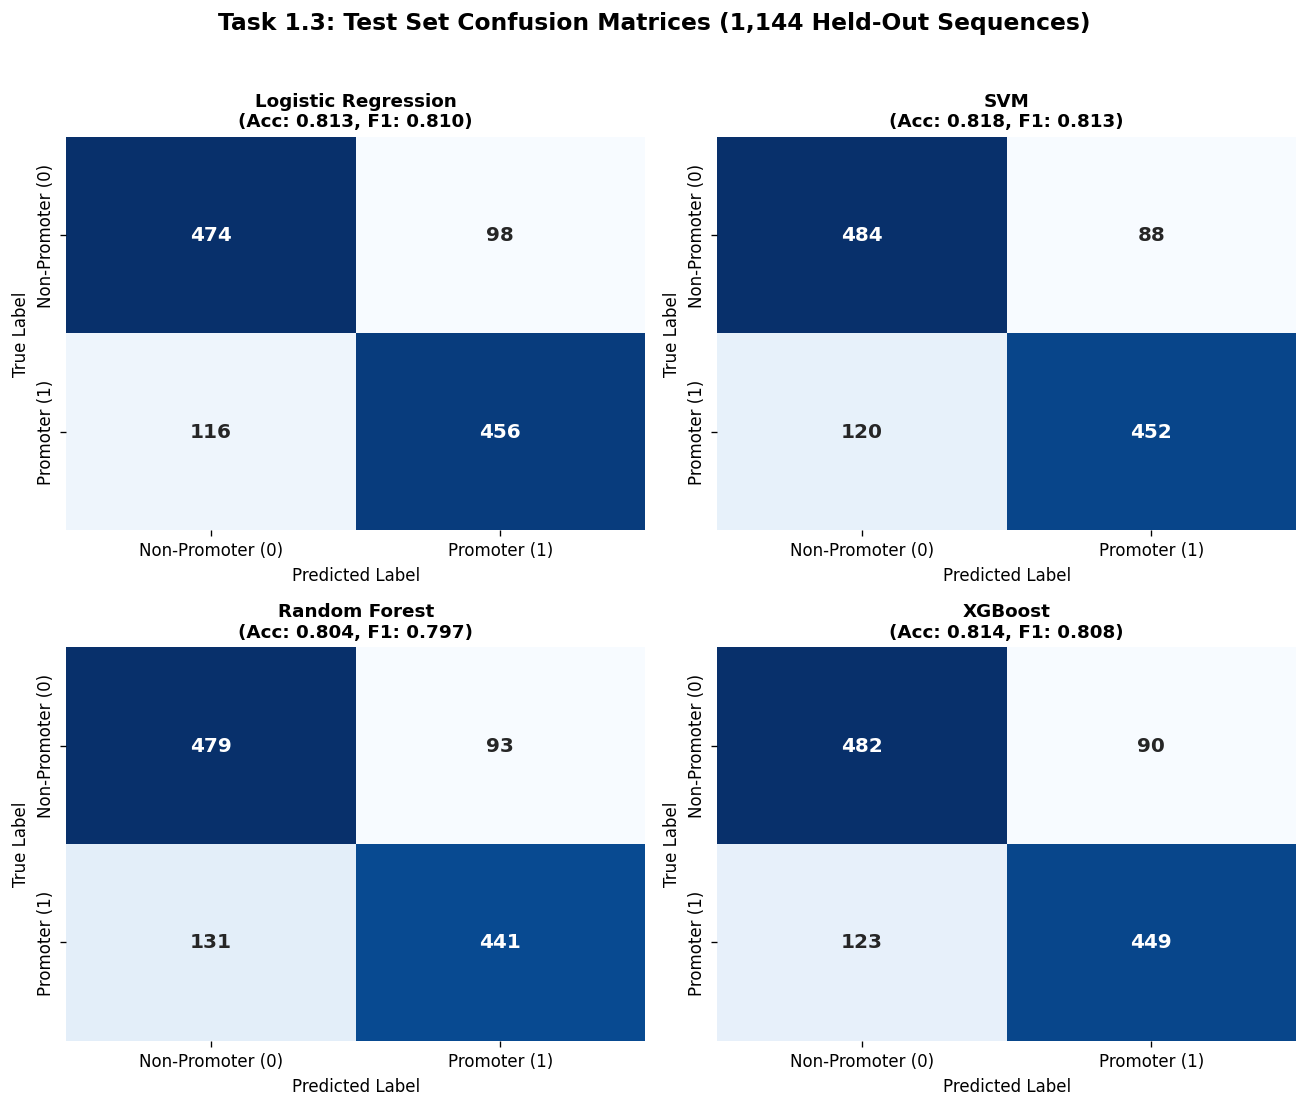

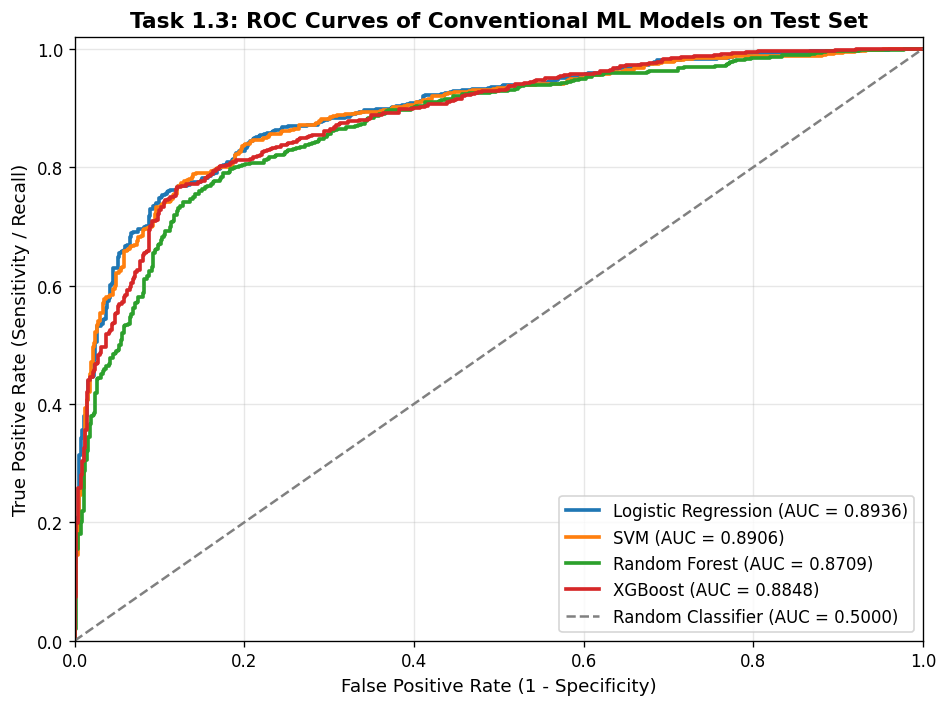

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9), dpi=120)
axes = axes.flatten()

for idx, (model_name, cm) in enumerate(confusion_matrices.items()):
    # Reuse already-computed metrics from results_df instead of calling .predict() again
    row_m = results_df[results_df["Model"] == model_name].iloc[0]
    acc, f1 = row_m["Accuracy"], row_m["F1-Score"]
    
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[idx],
        xticklabels=["Non-Promoter (0)", "Promoter (1)"],
        yticklabels=["Non-Promoter (0)", "Promoter (1)"],
        annot_kws={"size": 12, "weight": "bold"}
    )
    axes[idx].set_title(f"{model_name}\n(Acc: {acc:.3f}, F1: {f1:.3f})", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

plt.suptitle("Task 1.3: Test Set Confusion Matrices (1,144 Held-Out Sequences)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("task1_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6), dpi=120)
for model_name, (fpr, tpr, auc) in roc_curves_data.items():
    plt.plot(fpr, tpr, linewidth=2.2, label=f"{model_name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1.5, label="Random Classifier (AUC = 0.5000)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)
plt.title("Task 1.3: ROC Curves of Conventional ML Models on Test Set", fontsize=13, fontweight="bold")
plt.legend(loc="lower right", frameon=True, fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("task1_roc_curves.png", dpi=300)
plt.show()

# 8. Inspecting Top Learned Biological Features (For Report Section 6.1 & 6b)

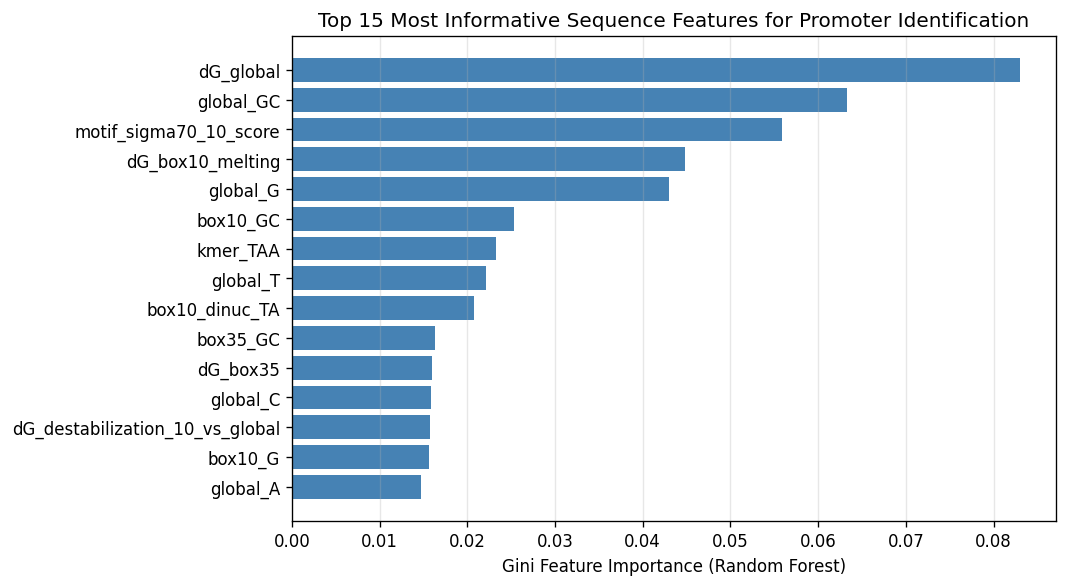

In [8]:
rf_clf = best_estimators["Random Forest"].named_steps["clf"]
importances = rf_clf.feature_importances_
top_indices = np.argsort(importances)[::-1][:15]

plt.figure(figsize=(9, 5), dpi=120)
plt.barh(
    [all_feature_names[i] for i in top_indices][::-1],
    importances[top_indices][::-1],
    color="steelblue"
)
plt.xlabel("Gini Feature Importance (Random Forest)")
plt.title("Top 15 Most Informative Sequence Features for Promoter Identification")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("task1_top15_features.png", dpi=300)
plt.show()

# 9. Saving Task 1 Metrics and ROC Data for Direct Integration with Task 3 CNN

In [9]:
# Section 3.2 & Section 6.2 require adding the Task 3 CNN to the Task 1 comparison table
# and comparing against the best Task 1 model on the exact same test set.
results_df.to_csv("task1_metrics_table.csv", index=False)

export_payload = {
    "metrics_df": results_df,
    "roc_curves": roc_curves_data,
    "confusion_matrices": confusion_matrices,
    "best_model_name": best_task1_model_name,
    "best_k": best_k,
}
with open("task1_results_for_task3.pkl", "wb") as f:
    pickle.dump(export_payload, f)

print("Saved 'task1_metrics_table.csv' and 'task1_results_for_task3.pkl' for Task 3 comparison.")

Saved 'task1_metrics_table.csv' and 'task1_results_for_task3.pkl' for Task 3 comparison.
